Dataset:
   ORDERNUMBER  QUANTITYORDERED  PRICEEACH  ORDERLINENUMBER    SALES  \
0        10107               30      95.70                2  2871.00   
1        10121               34      81.35                5  2765.90   
2        10134               41      94.74                2  3884.34   
3        10145               45      83.26                6  3746.70   
4        10159               49     100.00               14  5205.27   

         ORDERDATE   STATUS  QTR_ID  MONTH_ID  YEAR_ID  ...  \
0   2/24/2003 0:00  Shipped       1         2     2003  ...   
1    5/7/2003 0:00  Shipped       2         5     2003  ...   
2    7/1/2003 0:00  Shipped       3         7     2003  ...   
3   8/25/2003 0:00  Shipped       3         8     2003  ...   
4  10/10/2003 0:00  Shipped       4        10     2003  ...   

                    ADDRESSLINE1  ADDRESSLINE2           CITY STATE  \
0        897 Long Airport Avenue           NaN            NYC    NY   
1             59 rue de l'Abbaye     

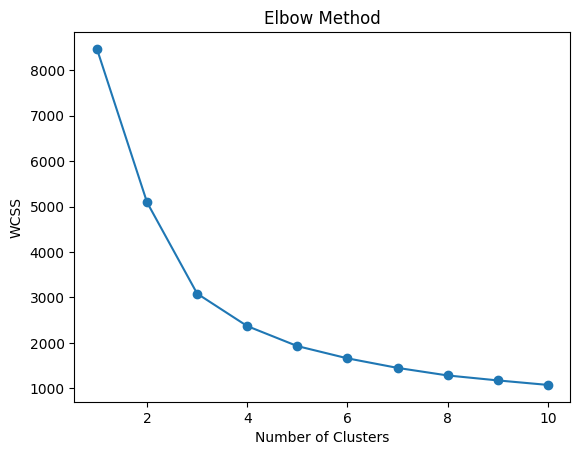


K-Means Clustering:
     SALES  KMeans_Cluster
0  2871.00               2
1  2765.90               2
2  3884.34               1
3  3746.70               1
4  5205.27               1

Hierarchical Clustering:
     SALES  Hierarchical_Cluster
0  2871.00                     2
1  2765.90                     2
2  3884.34                     1
3  3746.70                     0
4  5205.27                     1


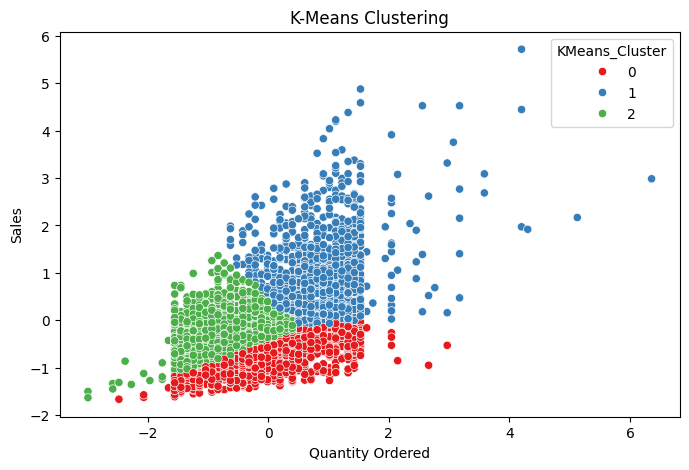

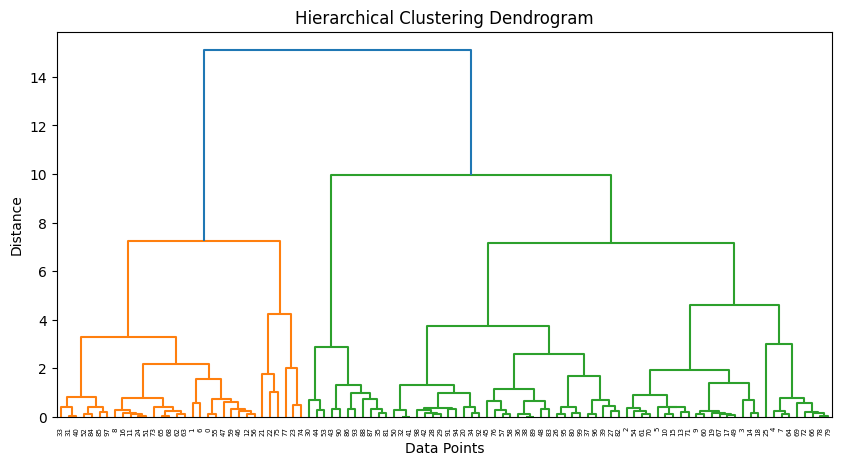


K-Means Cluster Counts:
KMeans_Cluster
2    1035
1     907
0     881
Name: count, dtype: int64

Hierarchical Cluster Counts:
Hierarchical_Cluster
2    1124
0    1014
1     685
Name: count, dtype: int64


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

# 1. Load Dataset
df = pd.read_csv("/kaggle/input/datasets/kyanyoga/sample-sales-data/sales_data_sample.csv", encoding="latin1")

print("Dataset:")
print(df.head())

# 2. Select Numerical Features
X = df[["QUANTITYORDERED", "PRICEEACH", "SALES"]]

# 3. Handle Missing Values
X = X.fillna(X.mean())

# 4. Feature Scaling
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 5. Elbow Method
wcss = []

for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

plt.plot(range(1, 11), wcss, marker='o')
plt.title("Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.show()

# 6. K-Means Clustering
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df["KMeans_Cluster"] = kmeans.fit_predict(X_scaled)

print("\nK-Means Clustering:")
print(df[["SALES", "KMeans_Cluster"]].head())

# 7. Hierarchical Clustering
hc = AgglomerativeClustering(n_clusters=3, linkage="ward")
df["Hierarchical_Cluster"] = hc.fit_predict(X_scaled)

print("\nHierarchical Clustering:")
print(df[["SALES", "Hierarchical_Cluster"]].head())

# 8. Plot K-Means Clusters
plt.figure(figsize=(8, 5))
sns.scatterplot(
    x=X_scaled[:, 0],
    y=X_scaled[:, 2],
    hue=df["KMeans_Cluster"],
    palette="Set1"
)
plt.title("K-Means Clustering")
plt.xlabel("Quantity Ordered")
plt.ylabel("Sales")
plt.show()

# 9. Dendrogram
Z = linkage(X_scaled[:100], method="ward")

plt.figure(figsize=(10, 5))
dendrogram(Z)
plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Data Points")
plt.ylabel("Distance")
plt.show()

# 10. Cluster Counts
print("\nK-Means Cluster Counts:")
print(df["KMeans_Cluster"].value_counts())

print("\nHierarchical Cluster Counts:")
print(df["Hierarchical_Cluster"].value_counts())